# NB2 · The Brain: how an LLM works

**Agentic Systems Engineering · Lecture 2 · Vizuara · Dr. Rajat Dandekar**

You are the engineer **Northbridge Cycles** hired to make it AI-native. Northbridge builds electric bikes in
Manchester and runs on **Ledgerline ERP 7.2**. Its assistant, **Ask Northbridge**, starts as a brain alone: a
large language model (LLM) with no tools and no Northbridge data. On Monday 26 October 2026 Emma Clarke, a purchase
executive, asks it:

> **How many city e-bike battery packs do we have in Manchester stores?**

Ledgerline says **5,400**. Ask Northbridge answers at once, with a number, and the number is made up.
In this notebook we follow that one question through a real language model, in the same nine steps as the lecture:

1. the game: predict the next token
2. what you send, cut into tokens (and what it costs)
3. each token becomes a vector
4. attention: tokens look back
5. a block, then 24 of them
6. from a vector to a choice (temperature)
7. the loop: one token at a time
8. where the weights came from: a tiny GPT trained on Northbridge's own documents, and the cut-off
9. why it made the number up, and what fixes it

**The model we open.** We can't open Gemini, so we open a small open model of the same kind,
**Qwen2.5-0.5B-Instruct**, with the app's own system prompt. It runs on the free Colab CPU (about 1 GB to download).
If the download fails, the Qwen cells use the numbers we recorded on Modal with the same model and prompt
(`ledgerline/course/l2/rec_qwen.json`) and say so.

**The Gemini calls are replayed.** Ask Northbridge is gemini-3.8-flash. Its replies come from our recorded runs
(cassettes `L2v4_*`), so the notebook needs no API key and shows exactly what happened.

Six exercises are marked `TODO (exercise N)`. Each one has its solution in place behind `SOLUTION = True`, so the
notebook runs top to bottom. Set it to `False` and try it yourself.

In [1]:
# Setup: install the Ledgerline sandbox and its recorded model replies. Runs in about a minute on Colab.
# REPLAY mode (the default when you have no key) plays back our recorded model calls, so every cell runs
# without an API key and shows the numbers from our own run. To call a model live, set a key below.
import os, sys, subprocess
COURSE_REPO = "https://github.com/RajatDandekar/agents-for-enterprises"   # course code (Ledgerline sandbox + reference agent)
try:
    import ledgerline  # already available (local checkout or Modal)
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"ledgerline-erp[all] @ git+{COURSE_REPO}.git#subdirectory=ledgerline"], check=True)
    import ledgerline
# os.environ["GEMINI_API_KEY"] = "..."        # optional: your own key, to run live
# os.environ["OPENROUTER_API_KEY"] = "..."    # optional: GPT, Claude, Llama ... via OpenRouter
os.environ.setdefault("LEDGER_LLM_MODE", "auto")  # auto = replay what was recorded, call live only for new requests
print("Ledgerline", ledgerline.__version__, "· model mode:", os.environ["LEDGER_LLM_MODE"])

Ledgerline 0.1.0 · model mode: replay


In [2]:
# Torch and transformers are already on Colab. Elsewhere (a plain Python image) we install the CPU wheels.
import importlib, subprocess, sys, time, json, math, re
for mod, args in [("torch", ["torch", "--index-url", "https://download.pytorch.org/whl/cpu"]),
                  ("transformers", ["transformers>=4.44,<4.50"])]:
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args], check=True)
import numpy as np
import torch
import matplotlib.pyplot as plt
import importlib.resources as ir
from ledgerline.course.l2 import brain
from ledgerline.course.l2.brain import BrainOnly, QUESTION, SYSTEM_BRAIN, TRUE_ANSWER
torch.manual_seed(0)
REC = brain.load("rec_qwen")   # what this notebook computes with Qwen, recorded on Modal (the replay fallback)
print("torch", torch.__version__)
print("The app's brain-stage system prompt (ledgerline/experience/harness.py):\n")
print(SYSTEM_BRAIN)
print("\nEmma:", QUESTION)


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


torch 2.15.0+cpu
The app's brain-stage system prompt (ledgerline/experience/harness.py):

You are Ask Northbridge, the assistant on the home page of Northbridge Cycles, Manchester, a maker of e-bikes.
You are talking to Emma Clarke, purchase executive. Today is Monday 26 October 2026. Help with purchasing: stock, orders,
approvals and receipts. Keep replies short and plain. No emoji.

Emma: How many city e-bike battery packs do we have in Manchester stores?


In [3]:
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
LIVE = True
try:
    from transformers import AutoTokenizer, AutoModelForCausalLM
    t0 = time.time()
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float32, attn_implementation="eager").eval()
    torch.set_grad_enabled(False)
    print(f"Loaded {MODEL_NAME} in {time.time() - t0:.0f} s:", f"{sum(p.numel() for p in model.parameters()):,}", "numbers (parameters)")
except Exception as e:  # no internet or no disk: use what we recorded on Modal
    LIVE = False
    print("Could not load the model here, so the Qwen cells REPLAY our recorded numbers. Reason:", str(e)[:200])
show = (lambda i: tok.decode([int(i)])) if LIVE else None


def chat_ids(system, question=QUESTION):
    """The chat as the model sees it: the chat template turns the messages into one text, then into token ids."""
    msgs = [{"role": "system", "content": system}, {"role": "user", "content": question}]
    text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    return text, tok(text, add_special_tokens=False).input_ids


if LIVE:
    CHAT_TEXT, IDS = chat_ids(SYSTEM_BRAIN)
    print(CHAT_TEXT)
    print("same token ids as our recorded run:", IDS == REC["ids"])
else:
    IDS = REC["ids"]
    print("".join(p[0] for p in REC["pieces"]))

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

Sliding Window Attention is enabled but not implemented for `eager`; unexpected results may be encountered.


generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded Qwen/Qwen2.5-0.5B-Instruct in 4 s: 494,032,768 numbers (parameters)
<|im_start|>system
You are Ask Northbridge, the assistant on the home page of Northbridge Cycles, Manchester, a maker of e-bikes.
You are talking to Emma Clarke, purchase executive. Today is Monday 26 October 2026. Help with purchasing: stock, orders,
approvals and receipts. Keep replies short and plain. No emoji.<|im_end|>
<|im_start|>user
How many city e-bike battery packs do we have in Manchester stores?<|im_end|>
<|im_start|>assistant

same token ids as our recorded run: True


## 1 · The game: predict the next token
A language model plays one game. Given the text so far, it gives **a probability to every possible next token**
(a token is a piece of text; section 2 shows exactly what). We give Qwen the whole chat above and ask: what comes
first in the answer?

In [4]:
def next_token(id_list, k=10):
    """Top-k next tokens: [text, id, logit, probability], plus the top 60 logits (used in section 6)."""
    logits = model(torch.tensor([id_list])).logits[0, -1]
    p = torch.softmax(logits, -1)
    top = torch.topk(logits, 60)
    return {"top": [[show(i), int(i), round(float(l), 3), round(float(p[i]), 5)] for l, i in zip(top.values[:k], top.indices[:k])],
            "logits60": [[show(i), round(float(l), 3)] for l, i in zip(top.values, top.indices)]}


NEXT = next_token(IDS) if LIVE else REC["next_answer"]
for text, tid, logit, p in NEXT["top"]:
    print(f"{text!r:14} id {tid:6}  p = {p:.4f}  " + "#" * int(60 * p))
if LIVE:
    print("\nsame top 5 as our recorded run:", [t[1] for t in NEXT["top"][:5]] == [t[1] for t in REC["next_answer"]["top"][:5]])

'We'           id   1654  p = 0.5637  #################################
'As'           id   2121  p = 0.0792  ####
'Manchester'   id  74243  p = 0.0614  ###
'In'           id    641  p = 0.0528  ###
'Our'          id   7981  p = 0.0417  ##
'At'           id   1655  p = 0.0282  #
'There'        id   3862  p = 0.0245  #
'Currently'    id  33714  p = 0.0174  #
'I'            id     40  p = 0.0164  
'The'          id    785  p = 0.0153  

same top 5 as our recorded run: True


Those numbers are a **probability distribution**: one number for every token of the vocabulary (the next cell
counts them), all adding up to 1. The model does not look anything up. It has learnt which tokens tend to come next.

The same game on a plain stock line, with no chat around it. The next token is the start of a stock figure:

In [5]:
if LIVE:
    print("vocabulary:", f"{len(tok):,}", "tokens; the probabilities add up to",
          round(float(torch.softmax(model(torch.tensor([IDS])).logits[0, -1], -1).sum()), 4))
RAW = REC["raw_prompt"]
RAW_NEXT = next_token(tok(RAW, add_special_tokens=False).input_ids) if LIVE else REC["next_raw"]
print(repr(RAW))
for text, tid, logit, p in RAW_NEXT["top"]:
    print(f"{text!r:8} p = {p:.4f}  " + "#" * int(60 * p))

vocabulary: 151,665 tokens; the probabilities add up to 1.0


'City e-bike battery packs (BAT-500) in Manchester stores: '
'1'      p = 0.2756  ################
'2'      p = 0.2011  ############
'5'      p = 0.1095  ######
'3'      p = 0.1079  ######
'4'      p = 0.0896  #####
'7'      p = 0.0529  ###
'6'      p = 0.0516  ###
'8'      p = 0.0449  ##
'9'      p = 0.0423  ##
'0'      p = 0.0119  


Every digit gets some probability, because the model has seen millions of stock lines, but never Northbridge's.
Nothing in the prompt says 5,400, so "5" is just one plausible start among many.

### TODO (exercise 1): softmax by hand
The model's raw scores are called **logits**. Softmax turns them into probabilities:
$p_i = e^{z_i} / \sum_j e^{z_j}$. Take the top 5 logits of the answer's first token (`NEXT["logits60"][:5]`) and
compute their probabilities **among themselves**, so the five add up to 1.

In [6]:
top5 = NEXT["logits60"][:5]
print(top5)
SOLUTION = True
if SOLUTION:
    z = np.array([l for _, l in top5])
    probs = np.exp(z - z.max()) / np.exp(z - z.max()).sum()   # subtract the max first: same result, no overflow
    for (t, _), p in zip(top5, probs):
        print(f"{t!r:12} {p:.3f}")

[['We', 20.842], ['As', 18.88], ['Manchester', 18.624], ['In', 18.475], ['Our', 18.238]]
'We'         0.706
'As'         0.099
'Manchester' 0.077
'In'         0.066
'Our'        0.052


## 2 · What you send, cut into tokens
Last section the model scored the next token. Now: what exactly did it read? Not letters, not words: **tokens**,
pieces of text from a fixed vocabulary, each with an id. Here is the whole chat, cut the way Qwen cuts it.
`[S]` is the app's system prompt, `[U]` is Emma's message, `[T]` is the chat template around them.

In [7]:
if LIVE:
    enc = tok(CHAT_TEXT, return_offsets_mapping=True, add_special_tokens=False)
    s0, u0 = CHAT_TEXT.index(SYSTEM_BRAIN), CHAT_TEXT.index(QUESTION)
    spans = {"system": (s0, s0 + len(SYSTEM_BRAIN)), "user": (u0, u0 + len(QUESTION))}
    PIECES = [[show(t), int(t), next((r for r, (x, y) in spans.items() if a >= x and b <= y and b > a), "template")]
              for t, (a, b) in zip(enc.input_ids, enc.offset_mapping)]
else:
    PIECES = REC["pieces"]
mark = {"system": "S", "user": "U", "template": "T"}
print(" ".join(f"[{mark[r]}]{t!r}" for t, i, r in PIECES))
counts = {r: sum(1 for p in PIECES if p[2] == r) for r in ("system", "user", "template")}
print("\n", len(PIECES), "tokens:", counts)
print("Emma's question:", len(QUESTION), "characters,", len(QUESTION.split()), "words,", counts["user"], "tokens")
print("ids of Emma's question:", [i for t, i, r in PIECES if r == "user"])

[T]'<|im_start|>' [T]'system' [T]'\n' [S]'You' [S]' are' [S]' Ask' [S]' North' [S]'bridge' [S]',' [S]' the' [S]' assistant' [S]' on' [S]' the' [S]' home' [S]' page' [S]' of' [S]' North' [S]'bridge' [S]' C' [S]'ycles' [S]',' [S]' Manchester' [S]',' [S]' a' [S]' maker' [S]' of' [S]' e' [S]'-b' [S]'ikes' [S]'.\n' [S]'You' [S]' are' [S]' talking' [S]' to' [S]' Emma' [S]' Clarke' [S]',' [S]' purchase' [S]' executive' [S]'.' [S]' Today' [S]' is' [S]' Monday' [S]' ' [S]'2' [S]'6' [S]' October' [S]' ' [S]'2' [S]'0' [S]'2' [S]'6' [S]'.' [S]' Help' [S]' with' [S]' purchasing' [S]':' [S]' stock' [S]',' [S]' orders' [S]',\n' [S]'appro' [S]'vals' [S]' and' [S]' receipts' [S]'.' [S]' Keep' [S]' replies' [S]' short' [S]' and' [S]' plain' [S]'.' [S]' No' [S]' emoji' [S]'.' [T]'<|im_end|>' [T]'\n' [T]'<|im_start|>' [T]'user' [T]'\n' [U]'How' [U]' many' [U]' city' [U]' e' [U]'-b' [U]'ike' [U]' battery' [U]' packs' [U]' do' [U]' we' [U]' have' [U]' in' [U]' Manchester' [U]' stores' [U]'?' [T]'<|im_end|>'

How Northbridge's own words and numbers are cut. Common words are one token; rare names split into pieces;
**every digit is its own token**, so a number is read (and later written) digit by digit.

In [8]:
for s in ["Manchester", " Manchester", " battery", " Northbridge", " Ledgerline", " Brightcell", " BAT-500", " 5,400", " £285,600"]:
    pcs = [tok.decode([i]) for i in tok(s, add_special_tokens=False).input_ids] if LIVE else [p[0] for p in REC["cuts"][s]["qwen"]]
    print(f"{s!r:16} -> {len(pcs)} tokens: {pcs}")

'Manchester'     -> 1 tokens: ['Manchester']
' Manchester'    -> 1 tokens: [' Manchester']
' battery'       -> 1 tokens: [' battery']
' Northbridge'   -> 2 tokens: [' North', 'bridge']
' Ledgerline'    -> 2 tokens: [' Ledger', 'line']
' Brightcell'    -> 2 tokens: [' Bright', 'cell']
' BAT-500'       -> 5 tokens: [' BAT', '-', '5', '0', '0']
' 5,400'         -> 6 tokens: [' ', '5', ',', '4', '0', '0']
' £285,600'      -> 8 tokens: [' £', '2', '8', '5', ',', '6', '0', '0']


### Why tokens and not words?
Why not give the model one id per word? Build a word vocabulary from Northbridge's own text (the corpus we train a
tiny GPT on in section 8), then read two Northbridge documents that are not in it: the Ledgerline user manual and the
data dictionary.

In [9]:
WORD = re.compile(r"[A-Za-z0-9£§][A-Za-z0-9£§.,/'-]*[A-Za-z0-9]|[A-Za-z0-9]")
corpus_text = (ir.files("ledgerline.course.l2") / "northbridge_corpus.md").read_text()
vocab_words = set(WORD.findall(corpus_text))
new_words = []
for name in ("user-manual.md", "data-dictionary.md"):
    new_words += WORD.findall((ir.files("ledgerline") / "docs" / name).read_text())
unknown = [w for w in new_words if w not in vocab_words]
print(f"word vocabulary from the corpus: {len(vocab_words):,} words")
print(f"the two new documents: {len(new_words):,} words, of which {len(unknown):,} ({len(unknown) / len(new_words):.0%}) are not in it")
print("for example:", sorted(set(unknown), key=unknown.count, reverse=True)[:15])
manual = (ir.files("ledgerline") / "docs" / "user-manual.md").read_text()
if LIVE:
    m_ids = tok(manual, add_special_tokens=False).input_ids
    print(f"\nQwen's tokens: {len(m_ids):,} for the manual's {len(manual):,} characters ({len(manual) / len(m_ids):.1f} characters a token),"
          f" and decoding them gives the text back exactly: {tok.decode(m_ids) == manual}")

word vocabulary from the corpus: 1,312 words
the two new documents: 6,004 words, of which 1,978 (33%) are not in it
for example: ['Cause', 'Remedy', 'F2', 'field', 'press', 'you', 'user', 'cd', 'Save', 'AP', 'saved', 'Item', 'see', 'list', 'PA']

Qwen's tokens: 8,178 for the manual's 32,491 characters (4.0 characters a token), and decoding them gives the text back exactly: True


A word vocabulary meets new words all the time (codes, names, numbers, typos), and a model can do nothing with
a word it has no id for. Single characters never miss, but make every text very long. Tokens sit in between:
frequent pieces become one token, and anything else falls back to smaller pieces, down to single bytes.
Nothing is ever unknown.

The vocabulary is learnt by **byte-pair encoding (BPE)**: start from single characters, then again and again merge
the most frequent neighbouring pair into a new token. Here it is by hand on a tiny Northbridge text. `_` marks the
end of a word.

### TODO (exercise 2): one BPE merge
Write `merge(words, pair)`: inside every word, join each occurrence of `pair` into one token.

In [10]:
tiny_text = "battery batteries pack packs battery pack charger chargers battery packs pack battery"
words = {}
for w in tiny_text.split():
    words[tuple(w) + ("_",)] = words.get(tuple(w) + ("_",), 0) + 1


def pair_counts(words):
    pairs = {}
    for w, n in words.items():
        for a, b in zip(w, w[1:]):
            pairs[(a, b)] = pairs.get((a, b), 0) + n
    return pairs


SOLUTION = True
if SOLUTION:
    def merge(words, pair):
        new = {}
        for w, n in words.items():
            out, i = [], 0
            while i < len(w):
                if i < len(w) - 1 and (w[i], w[i + 1]) == pair:
                    out.append(w[i] + w[i + 1]); i += 2
                else:
                    out.append(w[i]); i += 1
            new[tuple(out)] = n
        return new

vocab = sorted({c for w in words for c in w})
print("start:", len(vocab), "tokens in the vocabulary,", sum(len(w) * n for w, n in words.items()), "tokens in the text")
for step in range(1, 11):
    pc = pair_counts(words)
    best = max(pc, key=pc.get)
    words = merge(words, best)
    vocab.append(best[0] + best[1])
    print(f"merge {step:2}: {best[0]!r} + {best[1]!r} (seen {pc[best]}x) -> vocabulary {len(vocab)}, text "
          f"{sum(len(w) * n for w, n in words.items())} tokens | batteries = {[w for w in words if ''.join(w) == 'batteries_'][0]}")

start: 14 tokens in the vocabulary, 86 tokens in the text
merge  1: 'e' + 'r' (seen 7x) -> vocabulary 15, text 79 tokens | batteries = ('b', 'a', 't', 't', 'er', 'i', 'e', 's', '_')
merge  2: 'b' + 'a' (seen 5x) -> vocabulary 16, text 74 tokens | batteries = ('ba', 't', 't', 'er', 'i', 'e', 's', '_')
merge  3: 'ba' + 't' (seen 5x) -> vocabulary 17, text 69 tokens | batteries = ('bat', 't', 'er', 'i', 'e', 's', '_')
merge  4: 'bat' + 't' (seen 5x) -> vocabulary 18, text 64 tokens | batteries = ('batt', 'er', 'i', 'e', 's', '_')
merge  5: 'batt' + 'er' (seen 5x) -> vocabulary 19, text 59 tokens | batteries = ('batter', 'i', 'e', 's', '_')
merge  6: 'p' + 'a' (seen 5x) -> vocabulary 20, text 54 tokens | batteries = ('batter', 'i', 'e', 's', '_')
merge  7: 'pa' + 'c' (seen 5x) -> vocabulary 21, text 49 tokens | batteries = ('batter', 'i', 'e', 's', '_')
merge  8: 'pac' + 'k' (seen 5x) -> vocabulary 22, text 44 tokens | batteries = ('batter', 'i', 'e', 's', '_')
merge  9: 'batter' + 'y' (se

Qwen's tokenizer did the same with about 151,000 merges learnt from a huge amount of text. Text in other languages
and scripts is cut into more pieces, so the same question costs more tokens:

In [11]:
for lang, d in REC["languages"].items():
    n = len(tok(d["text"], add_special_tokens=False).input_ids) if LIVE else d["qwen"]
    print(f"{lang:9} {d['chars']:3} characters -> {n:3} tokens  {d['text']}")

English    67 characters ->  15 tokens  How many city e-bike battery packs do we have in Manchester stores?
German     71 characters ->  18 tokens  Wie viele Akkus für City-E-Bikes haben wir in den Lagern in Manchester?
Dutch      75 characters ->  24 tokens  Hoeveel accu's voor stads-e-bikes hebben we in de magazijnen in Manchester?
Polish     85 characters ->  27 tokens  Ile akumulatorów do miejskich rowerów elektrycznych mamy w magazynach w Manchesterze?
Greek      81 characters ->  72 tokens  Πόσες μπαταρίες για ηλεκτρικά ποδήλατα πόλης έχουμε στις αποθήκες του Μάντσεστερ;
Japanese   39 characters ->  31 tokens  マンチェスターの倉庫に、シティ電動自転車のバッテリーパックはいくつありますか？


### What the question costs
Tokens are what you pay for. Gemini counts its own tokens (its tokenizer differs from Qwen's). We replay the first
recorded run of Ask Northbridge, the app at `?stage=brain`, and read what Gemini counted.

In [12]:
a1 = BrainOnly("L2v4_coldopen_r1")
r1 = a1.respond(QUESTION)
print("Ask Northbridge:", r1["reply"])
print(f"\ntokens in {r1['tokens_in']} (system prompt + question + chat format), tokens out {r1['tokens_out']}, model {r1['model']}")
from ledgerline.llm import PRICES
print("list price, US dollars per million tokens (in, out):", PRICES["gemini-3.8-flash"], "| £ = $ x", brain.USD_GBP)
print("the provider's whole usage record for the same request:", REC["usage_record"])

Ask Northbridge: There are currently 42 City e-bike battery packs in stock across the Manchester stores:

- Central Warehouse: 35
- Assembly Store: 7

Let me know if you need to check pending purchase orders or raise a new request.

tokens in 90 (system prompt + question + chat format), tokens out 52, model gemini:gemini-3.8-flash
list price, US dollars per million tokens (in, out): (0.5, 3.0) | £ = $ x 0.79
the provider's whole usage record for the same request: {'completion_tokens': 43, 'prompt_tokens': 90, 'total_tokens': 523, 'completion_tokens_details': None, 'prompt_tokens_details': None}


### TODO (exercise 3): the price in pounds
1. Compute the cost of this one question in pounds from `r1["tokens_in"]`, `r1["tokens_out"]` and the prices above.
2. Gemini 3 also **thinks** before it answers, and thinking tokens are billed as output. In the usage record,
   `total_tokens - prompt_tokens - completion_tokens` is the thinking. Compute the cost with the thinking included.
3. What would 1,000 such questions a day cost for a year?

In [13]:
SOLUTION = True
if SOLUTION:
    p_in, p_out = PRICES["gemini-3.8-flash"]
    visible = (r1["tokens_in"] * p_in + r1["tokens_out"] * p_out) / 1e6 * brain.USD_GBP
    u = REC["usage_record"]
    thinking = u["total_tokens"] - u["prompt_tokens"] - u["completion_tokens"]
    billed = (u["prompt_tokens"] * p_in + (u["completion_tokens"] + thinking) * p_out) / 1e6 * brain.USD_GBP
    print(f"visible answer only: £{visible:.6f} a question")
    print(f"with {thinking} thinking tokens:  £{billed:.6f} a question, £{billed * 1000 * 365:,.2f} for 1,000 a day for a year")

visible answer only: £0.000159 a question
with 390 thinking tokens:  £0.001062 a question, £387.54 for 1,000 a day for a year


## 3 · Each token becomes a vector
Last section the question became a strip of token ids. Now each id is looked up in the **embedding table**: one
row of 896 numbers per token. Those 896 numbers are where the meaning starts. Tokens used in similar ways get
similar vectors; **cosine similarity** (1 = same direction, 0 = unrelated) measures it.

In [14]:
if LIVE:
    E = model.get_input_embeddings().weight          # [151,936 rows, 896 numbers]
    En = E / E.norm(dim=1, keepdim=True)
    bat = tok(" battery", add_special_tokens=False).input_ids[0]
    print("embedding table:", tuple(E.shape), "| ' battery' is id", bat, "| its first 8 numbers:", [round(float(v), 4) for v in E[bat][:8]])
    clean = torch.tensor([bool(re.fullmatch(r" [A-Za-z]{3,}", show(i))) for i in range(E.shape[0])])  # plain words only

    def neighbours(word, k=8):
        wid = tok(word, add_special_tokens=False).input_ids[0]
        sim = En @ En[wid]
        sim[~clean] = -2
        sim[wid] = -2
        res, seen = [], {word.strip().lower()}
        for s, i in zip(*sim.topk(40)):
            t = show(i)
            if t.strip().lower() in seen:
                continue
            seen.add(t.strip().lower())
            res.append([t, round(float(s), 3)])
            if len(res) == k:
                break
        return res

    NEIGH = {w.strip(): neighbours(w) for w in (" battery", " Manchester")}
    cos = lambda a, b: round(float(En[tok(a, add_special_tokens=False).input_ids[0]] @ En[tok(b, add_special_tokens=False).input_ids[0]]), 3)
    COS = {f"{a.strip()}|{b.strip()}": cos(a, b) for a, b in ((" battery", " charger"), (" battery", " Monday"),
                                                               (" Manchester", " Leeds"), (" Manchester", " battery"))}
else:
    print("' battery', first 8 numbers (recorded):", REC["battery_first8"])
    NEIGH, COS = REC["neighbours"], REC["cos"]
for w, nn in NEIGH.items():
    print(f"nearest to {w!r}:", ", ".join(f"{t.strip()} {s}" for t, s in nn))
print("cosine:", COS)

embedding table: (151936, 896) | ' battery' is id 11602 | its first 8 numbers: [-0.0031, 0.0119, -0.0154, 0.0044, -0.0001, 0.0117, 0.0201, -0.0132]


nearest to 'battery': batteries 0.774, Batter 0.532, lithium 0.396, capacitor 0.313, recharge 0.309, charger 0.301, electrode 0.287, voltage 0.282
nearest to 'Manchester': Liverpool 0.403, Nottingham 0.36, Leicester 0.356, Leeds 0.35, Glasgow 0.346, Birmingham 0.342, London 0.307, Newcastle 0.299
cosine: {'battery|charger': 0.301, 'battery|Monday': 0.04, 'Manchester|Leeds': 0.35, 'Manchester|battery': 0.017}


## 4 · Attention: tokens look back
Last section every token got a vector, on its own. But "packs" after "battery" is not "packs" after "six".
**Attention** lets each token mix in information from the tokens before it. Each token makes three vectors:
a **query** (what am I looking for?), a **key** (what do I contain?) and a **value** (what do I pass on?).
Its new vector is a weighted sum of the earlier values, weighted by how well its query matches their keys.
Four tokens with two numbers each, small enough to do with a pencil:

In [15]:
tokens = ["Emma", "needs", "2,000", "packs"]
Q = np.array([[1, 0], [1, 1], [0, 1], [0, 2]], float)
K = np.array([[2, 0], [0, 1], [1, 3], [1, 1]], float)
V = np.array([[4, 0], [0, 1], [0, 8], [2, 2]], float)


def softmax(x):
    e = np.exp(x - x.max(-1, keepdims=True)); return e / e.sum(-1, keepdims=True)


scores = Q @ K.T / np.sqrt(2)                        # 1. match every query with every key, scale by sqrt(d)
mask = np.tril(np.ones((4, 4))) > 0                  # 2. causal mask: a token sees only itself and earlier tokens
weights = softmax(np.where(mask, scores, -np.inf))   # 3. softmax per row: the weights add up to 1
out = weights @ V                                    # 4. weighted sum of the values
print("weights (row = the token that looks, column = the token looked at)\n", np.round(weights, 3))
print("new vector for 'packs':", np.round(out[3], 3))

weights (row = the token that looks, column = the token looked at)
 [[1.    0.    0.    0.   ]
 [0.67  0.33  0.    0.   ]
 [0.088 0.178 0.734 0.   ]
 [0.013 0.052 0.883 0.052]]
new vector for 'packs': [0.155 7.22 ]


### TODO (exercise 4): one row by hand
Compute the weights of "needs" (row 2) yourself: its two scores (it may see only "Emma" and "needs"), divide by √2,
softmax, then the weighted sum of those two values. Check against the matrix above.

In [16]:
SOLUTION = True
if SOLUTION:
    s = np.array([Q[1] @ K[0], Q[1] @ K[1]]) / np.sqrt(2)
    weights_needs = np.exp(s) / np.exp(s).sum()
    print(np.round(weights_needs, 3), np.round(weights_needs @ V[:2], 3))

[0.67 0.33] [2.679 0.33 ]


Now the real thing: Qwen has 24 blocks with 14 attention heads each. We read the weights with which the **last
position of the prompt** (where the answer starts) looks back at every earlier token, averaged over all heads and
blocks, then find the single head that looks hardest at "Manchester".

In [17]:
if LIVE:
    o = model(torch.tensor([IDS]), output_attentions=True, output_hidden_states=True)
    ATT = [[o.attentions[l][0, h, -1, :].tolist() for h in range(14)] for l in range(24)]   # [block][head][position]
else:
    ATT = REC["att_last"]
A = np.array(ATT)
toks = [p[0] for p in PIECES]
avg = A.mean(axis=(0, 1))
print("where the last position looks (average of 24 x 14 heads):")
for i in np.argsort(-avg)[:8]:
    print(f"  {toks[i]!r:18} position {i:3}  weight {avg[i]:.3f}")
man = [i for i, p in enumerate(PIECES) if p[2] == "user" and p[0].strip() == "Manchester"][0]
l, h = np.unravel_index(np.argmax(A[2:, :, man]), A[2:, :, man].shape)
print(f"\nthe head that looks hardest at ' Manchester' (blocks 3-24): block {l + 3}, head {h}, weight {A[l + 2, h, man]:.2f}")
print("no weight goes forward: the last position is the last token, and the mask hides nothing after it")

where the last position looks (average of 24 x 14 heads):
  '<|im_start|>'     position   0  weight 0.332
  '\n'               position  99  weight 0.125
  '?'                position  94  weight 0.047
  'assistant'        position  98  weight 0.042
  '\n'               position  96  weight 0.041
  '\n'               position  79  weight 0.030
  ' Manchester'      position  92  weight 0.029
  '.\n'              position  29  weight 0.019

the head that looks hardest at ' Manchester' (blocks 3-24): block 24, head 2, weight 0.65
no weight goes forward: the last position is the last token, and the mask hides nothing after it


Much of the weight sits on the very first token, `<|im_start|>`: heads with nothing useful to look at "rest" there.

## 5 · A block, then 24 of them
Last section: attention mixes information between tokens. A **block** is attention followed by a small neural
network (the MLP) that works on each token's vector alone, each step added on top of the vector it started from.
Qwen stacks 24 blocks. The **logit lens** asks, after each block, "if you had to answer now, what would you say?"
by sending the vector at the last position straight to the output layer.

In [18]:
if LIVE:
    LENS = []
    for l in range(1, 25):
        hs = o.hidden_states[l][0, -1]
        hs = hs if l == 24 else model.model.norm(hs)     # the last hidden state is already normalised
        p = torch.softmax(model.lm_head(hs), -1)
        v, ix = p.topk(3)
        LENS.append([l, [[show(i), round(float(q), 4)] for q, i in zip(v, ix)]])
else:
    LENS = REC["lens_last"]
short = lambda t: repr(t)[:18]   # some early guesses are long runs of code characters
for l, top in LENS:
    print(f"after block {l:2}: {short(top[0][0]):20} p={top[0][1]:.3f}   then {short(top[1][0])}, {short(top[2][0])}")
final = LENS[-1][1][0][0]
first = next(l for l, top in LENS if top[0][0] == final)
print(f"\nthe final answer's first token {final!r} is the top guess from block {first} on")

after block  1: '")));'              p=0.063   then '*sp', ' (^)('
after block  2: '/****************   p=0.265   then '换句话', '/////////////////
after block  3: '/****************   p=0.344   then ' (^)(', '(^)('
after block  4: '\')."'              p=0.284   then "')==", ' (^)('
after block  5: '."]'                p=0.186   then '换句话', '")));'
after block  6: '换句话'                p=0.253   then '")));', '\')."'
after block  7: '换句话'                p=0.283   then '\')."', "+')"
after block  8: '\')."'              p=0.280   then "','');\n", '//---------------
after block  9: '\')."'              p=0.739   then '换句话', "+')"
after block 10: '\')."'              p=0.509   then "','');\n", '换句话'
after block 11: '\')."'              p=0.792   then '//---------------, "','');\n"
after block 12: '//---------------   p=0.190   then '\')."', 'aston'
after block 13: '\')."'              p=0.056   then '.Getenv', "','');\n"
after block 14: '\')."'              p=0.060   then '//***************, 

In the early blocks the top guess is junk: bits of code and other languages. Words that could start an answer
appear only near the top of the stack, and the answer's first token wins in the last few blocks.

## 6 · From a vector to a choice
Last section, the last block's vector became scores over the whole vocabulary. Now the model must **pick one token**.
Divide the logits by a **temperature** T before the softmax. T = 0 means "always take the top token" (greedy, the
app's setting); T < 1 sharpens the bars; T > 1 flattens them so rarer tokens get a chance.

T = 0: top token 'We' gets p = 1.000
T = 0.7: top token 'We' gets p = 0.817
T = 1.2: top token 'We' gets p = 0.443


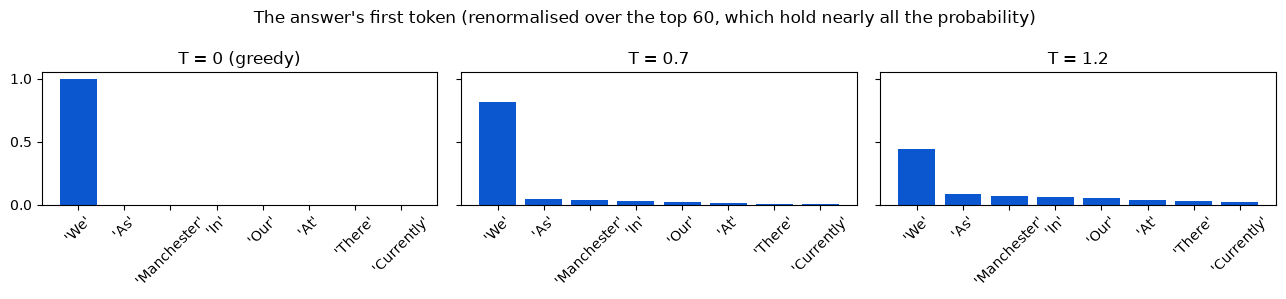

In [19]:
names = [t for t, _ in NEXT["logits60"]]
z = np.array([l for _, l in NEXT["logits60"]])
fig, axs = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
for ax, T in zip(axs, (0, 0.7, 1.2)):
    p = np.eye(len(z))[0] if T == 0 else np.exp((z - z.max()) / T) / np.exp((z - z.max()) / T).sum()
    ax.bar(range(8), p[:8], color="#0b57d0"); ax.set_xticks(range(8)); ax.set_xticklabels([repr(n) for n in names[:8]], rotation=45)
    ax.set_title(f"T = {T}" + (" (greedy)" if T == 0 else ""))
    print(f"T = {T}: top token {names[0]!r} gets p = {p[0]:.3f}")
plt.suptitle("The answer's first token (renormalised over the top 60, which hold nearly all the probability)")
plt.tight_layout(); plt.show()

## 7 · The loop: one token at a time
Last section the model picked one token. Now the picked token is added to the input and **the whole pass runs
again**, for the next one, and the next. That is how the answer grows, digits included. (A cache keeps the earlier
tokens' keys and values, so each step only computes the new token.)

In [20]:
def greedy(id_list, n=60):
    """Generate token by token, always taking the top token. Each step: [text, id, p, top-5 alternatives]."""
    seq, steps, past, x = list(id_list), [], None, torch.tensor([id_list])
    for _ in range(n):
        o = model(x, past_key_values=past, use_cache=True)
        past, lg = o.past_key_values, o.logits[0, -1]
        p = torch.softmax(lg, -1)
        nid = int(lg.argmax())
        v, ix = p.topk(5)
        steps.append([show(nid), nid, round(float(p[nid]), 4), [[show(i), round(float(q), 4)] for q, i in zip(v, ix)]])
        if nid == tok.convert_tokens_to_ids("<|im_end|>"):
            break
        seq.append(nid)
        x = torch.tensor([[nid]])
    return steps


STEPS = greedy(IDS) if LIVE else REC["greedy"]
answer = "".join(s[0] for s in STEPS if s[0] != "<|im_end|>")
for text, tid, p, alts in STEPS:
    flag = "   <- digit" if text.strip().isdigit() else ""
    print(f"{text!r:14} p={p:.3f}   alternatives: {', '.join(f'{a!r} {q:.2f}' for a, q in alts[1:3])}{flag}")
print("\nQwen's answer:", answer)
if LIVE:
    print("same answer as our recorded run:", answer == "".join(s[0] for s in REC["greedy"] if s[0] != "<|im_end|>"))
digits = [(t, p) for t, _, p, _ in STEPS if t.strip().isdigit()]
print("its digits and how sure it was of each:", digits)

'We'           p=0.564   alternatives: 'As' 0.08, 'Manchester' 0.06
' currently'   p=0.476   alternatives: ' have' 0.44, ' typically' 0.02
' have'        p=0.796   alternatives: ' stock' 0.12, ' carry' 0.02
' '            p=0.525   alternatives: ' a' 0.16, ' approximately' 0.07
'1'            p=0.336   alternatives: '2' 0.21, '5' 0.12   <- digit
'0'            p=0.323   alternatives: '5' 0.12, '2' 0.12   <- digit
'0'            p=0.542   alternatives: ' city' 0.30, ' battery' 0.03   <- digit
' city'        p=0.636   alternatives: '0' 0.14, ' battery' 0.09
' e'           p=0.983   alternatives: ' E' 0.01, ' electric' 0.00
'-b'           p=1.000   alternatives: '-B' 0.00, '-br' 0.00
'ike'          p=1.000   alternatives: 'ikes' 0.00, 'ik' 0.00
' battery'     p=0.999   alternatives: ' batteries' 0.00, ' (' 0.00
' packs'       p=1.000   alternatives: ' pack' 0.00, ' packages' 0.00
' available'   p=0.494   alternatives: ' in' 0.44, ' distributed' 0.02
' in'          p=0.599   alternatives: 

Qwen makes up a number too, one digit at a time, each digit just the likeliest next token. With sampling
(T = 0.7, the next cell) the made-up number changes from run to run.

In [21]:
def sample(id_list, T, seed, n=60):
    g = torch.Generator().manual_seed(seed)
    past, x, out_ids = None, torch.tensor([id_list]), []
    for _ in range(n):
        o = model(x, past_key_values=past, use_cache=True)
        past = o.past_key_values
        nid = int(torch.multinomial(torch.softmax(o.logits[0, -1] / T, -1), 1, generator=g))
        if nid == tok.convert_tokens_to_ids("<|im_end|>"):
            break
        out_ids.append(nid)
        x = torch.tensor([[nid]])
    return tok.decode(out_ids)


for s, rec_text in enumerate(REC["samples_t07"]):
    print(f"T=0.7 seed {s}:", sample(IDS, 0.7, s) if LIVE else rec_text + "  (recorded)")

T=0.7 seed 0: We currently have 100 city e-bike battery packs in our Manchester stores.


T=0.7 seed 1: Currently, we have approximately 100 city e-bike battery packs available at our Manchester stores.


T=0.7 seed 2: We currently have 44 city e-bike battery packs available for purchase in Manchester stores.


## 8 · Where the weights came from
Last section we watched 494 million fixed numbers produce an answer. Where did those numbers come from?
**Training**: start from random numbers, show the model text, and nudge every number so that the true next token
gets a higher probability. Qwen was trained that way on trillions of tokens. We can do the same, small, right
here: a **tiny GPT**, built from scratch, trained on Northbridge's own documents (purchase notes, stores entries,
e-mails and policy lines, all fictional), one character at a time.

In [22]:
import torch.nn as nn
import torch.nn.functional as F
torch.set_grad_enabled(True)   # the frozen Qwen above did not need gradients; training does


class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.n_head, self.d = n_head, n_embd // n_head
        self.qkv, self.proj, self.drop = nn.Linear(n_embd, 3 * n_embd), nn.Linear(n_embd, n_embd), nn.Dropout(dropout)
        self.register_buffer("mask", torch.tril(torch.ones(block_size, block_size)).bool())

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q, k, v = (t.view(B, T, self.n_head, self.d).transpose(1, 2) for t in (q, k, v))
        att = (q @ k.transpose(-2, -1)) / math.sqrt(self.d)          # section 4: query . key, scaled
        att = att.masked_fill(~self.mask[:T, :T], float("-inf"))    # no looking forward
        att = self.drop(F.softmax(att, dim=-1))
        return self.proj((att @ v).transpose(1, 2).contiguous().view(B, T, C))


class Block(nn.Module):                                              # section 5: attention + MLP
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.ln1, self.attn = nn.LayerNorm(n_embd), CausalSelfAttention(n_embd, n_head, block_size, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.mlp = nn.Sequential(nn.Linear(n_embd, 4 * n_embd), nn.GELU(), nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout))

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.mlp(self.ln2(x))


class TinyGPT(nn.Module):
    def __init__(self, vocab_size, block_size=128, n_layer=4, n_head=4, n_embd=128, dropout=0.1):
        super().__init__()
        self.block_size = block_size
        self.tok, self.pos = nn.Embedding(vocab_size, n_embd), nn.Embedding(block_size, n_embd)   # section 3
        self.blocks = nn.Sequential(*[Block(n_embd, n_head, block_size, dropout) for _ in range(n_layer)])
        self.ln_f, self.head = nn.LayerNorm(n_embd), nn.Linear(n_embd, vocab_size, bias=False)    # section 6

    def forward(self, idx, targets=None):
        x = self.tok(idx) + self.pos(torch.arange(idx.shape[1]))
        logits = self.head(self.ln_f(self.blocks(x)))
        loss = None if targets is None else F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, n, temperature=1.0, g=None):                                          # section 7
        for _ in range(n):
            logits, _ = self(idx[:, -self.block_size:])
            p = F.softmax(logits[:, -1, :] / temperature, dim=-1)
            idx = torch.cat([idx, torch.multinomial(p, 1, generator=g)], dim=1)
        return idx


text = corpus_text
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}
enc = lambda s: [stoi[c] for c in s]; dec = lambda ids: "".join(chars[i] for i in ids)
data = torch.tensor(enc(text)); n = int(0.9 * len(data)); train_d, val_d = data[:n], data[n:]
print(f"{len(text):,} characters, {len(chars)} distinct characters (the tiny GPT's whole vocabulary)\n")
print(text[:400])

122,069 characters, 81 distinct characters (the tiny GPT's whole vocabulary)

## 7. Rate contracts

Goods receipt, 13 Sep 2026: Aiko counted 1,250 BAT-500 against PO/2026/01177 at Leeds stores, delivery note DN-4458.

Goods receipt, 22 Aug 2026: Aiko counted 20,000 BOX-BIKE-01 against PO/2026/01152 at Manchester stores, delivery note DN-4464.

5.1 A supplier is BLOCKED in the master when: it has been replaced by a new code (for example after a merger or a change of VAT numb


### TODO (exercise 5): the loss before training
The loss is **cross-entropy**: the average of −log p(the true next character). Before training, the model spreads
its probability about evenly over the vocabulary. What loss do you expect? Compute it, then check step 0 below.

In [23]:
SOLUTION = True
if SOLUTION:
    expected_loss = math.log(len(chars))
    print(f"an even guess over {len(chars)} characters: loss = ln({len(chars)}) = {expected_loss:.3f}")

an even guess over 81 characters: loss = ln(81) = 4.394


830,464 parameters


BEFORE training:
 Stores, 26 Oct 2026: BAT-500 in Manchester stores,gr'0£E/vńF
2£9ilN4fkVo_
aCuA"q3Tb&?3"(pr)VhD;gńd?WMCkKtE£"N0EV-G)q%-"ń*§Ad5lX4Srh-k;?h?Cr"ń9bC.n
nAńrE?7Ko'DHnUV7wcnQGtń5QU%Vh(£L"k&1in"AFń"LIHby;vqng%uh:V%Vcdy 



step     0  train loss 4.592  validation loss 4.598  (1 s)


step   100  train loss 2.214  validation loss 2.228  (35 s)


step   200  train loss 1.161  validation loss 1.221  (67 s)


...

step  1100  train loss 0.282  validation loss 0.341  (367 s)


step  1200  train loss 0.263  validation loss 0.316  (400 s)


step  1300  train loss 0.247  validation loss 0.309  (434 s)


step  1400  train loss 0.232  validation loss 0.301  (468 s)


step  1500  train loss 0.226  validation loss 0.305  (500 s)


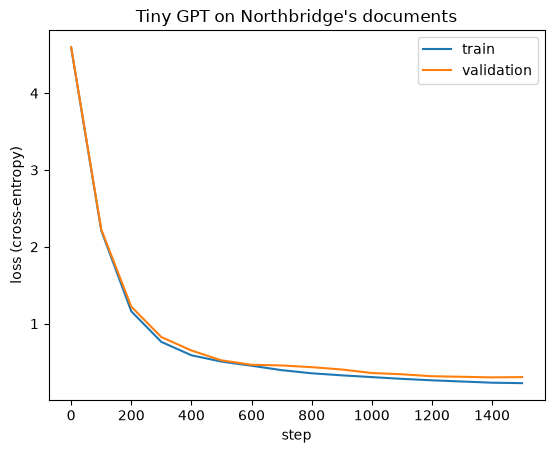

our recorded run on Modal (2 CPUs): {'step': 0, 'train': 4.5924, 'val': 4.5983, 'seconds': 2.5} -> {'step': 1500, 'train': 0.2267, 'val': 0.3037, 'seconds': 407.7}


In [24]:
torch.manual_seed(1337); g = torch.Generator().manual_seed(1337)
STEPS_T, BATCH, LR, BLOCK = 1500, 32, 2e-3, 128
gpt = TinyGPT(len(chars), BLOCK)
opt = torch.optim.AdamW(gpt.parameters(), lr=LR, weight_decay=0.01)
print(f"{sum(p.numel() for p in gpt.parameters()):,} parameters")


def batch(d):
    ix = torch.randint(len(d) - BLOCK - 1, (BATCH,), generator=g)
    return torch.stack([d[i:i + BLOCK] for i in ix]), torch.stack([d[i + 1:i + 1 + BLOCK] for i in ix])


def write(prompt, n=200, temperature=0.8, seed=0):
    gpt.eval()
    out_ = dec(gpt.generate(torch.tensor([enc(prompt)]), n, temperature, torch.Generator().manual_seed(seed))[0].tolist())
    gpt.train()
    return out_


STOCK_PROMPT = "Stores, 26 Oct 2026: BAT-500 in Manchester stores,"
print("BEFORE training:\n", write(STOCK_PROMPT, 160), "\n")
curve, t0 = [], time.time()
for step in range(STEPS_T + 1):
    if step % 100 == 0:
        gpt.eval()
        with torch.no_grad():
            tl = sum(gpt(*batch(train_d))[1].item() for _ in range(10)) / 10
            vl = sum(gpt(*batch(val_d))[1].item() for _ in range(10)) / 10
        gpt.train(); curve.append((step, tl, vl))
        print(f"step {step:5d}  train loss {tl:.3f}  validation loss {vl:.3f}  ({time.time() - t0:.0f} s)")
    if step == STEPS_T:
        break
    for gr in opt.param_groups:   # a short warm-up, then the learning rate decays along a cosine
        gr["lr"] = LR * min(1.0, (step + 1) / 100) * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * step / STEPS_T)))
    x, y = batch(train_d)
    _, loss = gpt(x, y)
    opt.zero_grad(set_to_none=True); loss.backward()
    torch.nn.utils.clip_grad_norm_(gpt.parameters(), 1.0); opt.step()
plt.plot([c[0] for c in curve], [c[1] for c in curve], label="train")
plt.plot([c[0] for c in curve], [c[2] for c in curve], label="validation")
plt.xlabel("step"); plt.ylabel("loss (cross-entropy)"); plt.legend(); plt.title("Tiny GPT on Northbridge's documents"); plt.show()
print("our recorded run on Modal (2 CPUs):", REC["tiny_curve"][0], "->", REC["tiny_curve"][-1])

Now let it write. Give it the start of a stores line, and it continues in Northbridge's style with a stock figure:
it has learnt what a stock line **looks like**, not what Northbridge **has**.

In [25]:
print(write("From: Emma Clarke\nTo: Daniel Okafor\nDate: 26 Oct 2026\nSubject:", 260))
print("---")
for s in range(5):
    print(write(STOCK_PROMPT, 40, 0.8, s))

From: Emma Clarke
To: Daniel Okafor
Date: 26 Oct 2026
Subject: Re: Battery packs for the spring launch run

Approved. Please raise the order raiser for a lithium-cell part. Buy it only from a supplier with a valid UN 38.3 certificate.

Order, 22 Oct 2026: PO/2026/01131 to Voltway Cells for 2,000 MNT-RCK-02, £89,000 gross
---
Stores, 26 Oct 2026: BAT-500 in Manchester stores, 28,900 on hand, using 6,000 a day, 10 d


Stores, 26 Oct 2026: BAT-500 in Manchester stores, 1,300 on hand, using 6,000 a day, 14 da
Stores, 26 Oct 2026: BAT-500 in Manchester stores, 35,800 on hand, using 200 a day, 12 day


Stores, 26 Oct 2026: BAT-500 in Manchester stores, 42,500 on hand, using 3,000 a day, 5 da
Stores, 26 Oct 2026: BAT-500 in Manchester stores, 28,900 on hand, using 6,500 a day, 4 da


### The cut-off
Training stops on some day, and the weights are frozen after it. Everything the model "knows" is text from before
that day. Our tiny GPT's last document is dated:

In [26]:
months = {"Aug": 8, "Sep": 9, "Oct": 10, "Nov": 11, "Dec": 12}
days = sorted({(months[m], int(d), m) for d, m in re.findall(r"\b(\d{1,2}) (Aug|Sep|Oct|Nov|Dec) 2026\b", corpus_text)})
print(f"the tiny GPT's documents run from {days[0][1]} {days[0][2]} 2026 to {days[-1][1]} {days[-1][2]} 2026")

the tiny GPT's documents run from 3 Aug 2026 to 23 Oct 2026


Qwen's cut-off shows in its probabilities. After "The current year is ", how likely is each year? (Each year is four
digit tokens, so its probability is the product of four next-token probabilities.)

In [27]:
def year_probs(prompt, years=range(2015, 2031)):
    base = tok(prompt, add_special_tokens=False).input_ids
    lp = {}
    for y in years:
        full = tok(prompt + str(y), add_special_tokens=False).input_ids
        seq, s_ = list(base), 0.0
        for t_ in full[len(base):]:
            p = torch.softmax(model(torch.tensor([seq])).logits[0, -1], -1)
            s_ += float(torch.log(p[t_])); seq.append(t_)
        lp[y] = s_
    tot = sum(math.exp(v) for v in lp.values())
    return {y: math.exp(v) / tot for y, v in lp.items()}


with torch.no_grad():
    if LIVE:
        yp = year_probs("The current year is ")
    else:
        yp = {r["year"]: r["p_among"] for r in REC["cutoff_qwen"]["year_probs"][0]["years"]}
for y, p in yp.items():
    print(y, f"{p:.3f}", "#" * int(80 * p))

2015 0.018 #
2016 0.020 #
2017 0.018 #
2018 0.021 #
2019 0.013 #
2020 0.009 
2021 0.078 ######
2022 0.204 ################
2023 0.546 ###########################################
2024 0.067 #####
2025 0.002 
2026 0.000 
2027 0.000 
2028 0.000 
2029 0.000 
2030 0.002 


In [28]:
from ledgerline.llm import LLM
co = LLM(brain.MODEL, cassette="L2v4_cutoff", max_tokens=4096)
CUT_Q = ("Without looking anything up: what is the most recent month and year that your training data covers? "
         "Answer with the month and year only.")
DATE_Q = "What is today's date? Answer with the date only."
print("Gemini, on its training data:", co.chat([{"role": "user", "content": CUT_Q}]).content)
print("Gemini, today's date, no system prompt:", co.chat([{"role": "user", "content": DATE_Q}]).content)
print("Gemini, today's date, the app's system prompt:", co.chat(brain.messages(DATE_Q)).content)

Gemini, on its training data: March 2026
Gemini, today's date, no system prompt: May 19, 2024
Gemini, today's date, the app's system prompt: 26 October 2026


The model's own idea of "now" comes from its training data. The app's system prompt says "Today is Monday
26 October 2026", and that is the only reason Ask Northbridge knows the date. Northbridge's stock this morning is
in no training data at all: it is private, and it changes every day.

## 9 · Why it made the number up, and what fixes it
We now have the whole machine. Here is Ask Northbridge (gemini-3.8-flash at `?stage=brain`) answering Emma's
question in eight separate runs at the app's own settings (replayed):

In [29]:
figures = []
for i in range(1, 9):
    r = BrainOnly(f"L2v4_coldopen_r{i}").respond(QUESTION)
    n_ = re.findall(r"\d[\d,]*\d|\d", r["reply"].strip().split("\n")[0])   # the first number in its first line
    figures.append(int(n_[0].replace(",", "")) if n_ else None)
    print(f"run {i}: {r['reply'][:150]!r}")
print("\nthe figures it gave:", figures, "| Ledgerline:", TRUE_ANSWER, "| right:", figures.count(TRUE_ANSWER), "of 8")
f = a1.respond(brain.FOLLOW_UP)
print("\nEmma: Where did that number come from?\nAsk Northbridge:", f["reply"])

run 1: 'There are currently 42 City e-bike battery packs in stock across the Manchester stores:\n\n- Central Warehouse: 35\n- Assembly Store: 7\n\nLet me know if y'
run 2: 'We currently have 48 City e-bike battery packs across Manchester locations:\n\n- Manchester Central Store: 12 units\n- Manchester Main Warehouse: 36 unit'
run 3: 'We currently have 48 City e-bike battery packs in stock in Manchester: 36 at the main assembly warehouse and 12 at the retail store.'
run 4: 'There are 42 city e-bike battery packs currently in stock at the Manchester stores:\n\n- Available: 34 units\n- Allocated to production: 8 units\n\nLet me '
run 5: 'We currently have 42 city e-bike battery packs in stock at the Manchester warehouse. An additional 15 units are currently reserved for production this'
run 6: 'We currently have 42 City e-bike battery packs in stock at the Manchester store. \n\nAn additional 25 units are on purchase order, scheduled for deliver'
run 7: 'We currently have 54 City e-bike ba

Trace the number back through the nine steps. The input (section 2) held a system prompt and a question, and no
stock figure. The vectors (3) and attention (4) could only mix what was in the input. The blocks (5) and the choice
(6, 7) produced the likeliest **kind** of answer, a confident sentence with a number, digit by digit. The weights (8)
hold patterns from text before the cut-off, and Northbridge's stock was never in that text. The number is plausible,
and it is invented. It even invents a source when asked.

### TODO (exercise 6): put the fact in the prompt
Make the system prompt carry one Ledgerline stock line: `SYSTEM_BRAIN`, a newline, then `brain.FACT`. Ask the same
question with `BrainOnly("L2v4_facts_r1", system=...)` (replayed). Then give Qwen the same prompt.

In [30]:
print("the fact line:", brain.FACT)
SOLUTION = True
if SOLUTION:
    system_with_fact = SYSTEM_BRAIN + "\n" + brain.FACT
    rf = BrainOnly("L2v4_facts_r1", system=system_with_fact).respond(QUESTION)
    print("Ask Northbridge with the fact:", rf["reply"])
    if LIVE:
        _, ids_f = chat_ids(system_with_fact)
        torch.set_grad_enabled(False)
        print("Qwen with the fact:", "".join(s[0] for s in greedy(ids_f) if s[0] != "<|im_end|>"))
    else:
        print("Qwen with the fact (recorded):", REC["greedy_facts_text"])

the fact line: Ledgerline stock, BAT-500 at Manchester main stores: 5,400 on hand
Ask Northbridge with the fact: There are 5,400 BAT-500 battery packs on hand at the Manchester main stores.


Qwen with the fact: We have 5,400 city e-bike battery packs in Manchester stores.


Same model, same weights, same question: with the fact in its input, the next-token game produces 5,400. Two ways
to get facts into the input are the next two lectures:
- **knowledge** (Lecture 3): find the right passages of Northbridge's documents and put them in the prompt;
- **tools** (Lecture 4): let the model ask Ledgerline itself. Offered two tools, it asks instead of guessing:

In [31]:
from ledgerline.erp.engine import ERP
from ledgerline.toolbox import Toolbox
tools = Toolbox(ERP(), "ECLARKE", names=["find_item", "check_stock"]).schemas()
t = LLM(brain.MODEL, cassette="L2v4_toolpreview", max_tokens=4096).chat(brain.messages(), tools=tools)
print("tools offered:", [x["function"]["name"] for x in tools])
print("what the model sends back:", [(c.name, c.arguments) for c in t.tool_calls], "| text:", t.content)

tools offered: ['find_item', 'check_stock']
what the model sends back: [('find_item', {'query': 'city e-bike battery pack'})] | text: None


## Your own documents (starts Assignment A2)
Paste a page of your own work's documents below (a policy, a report, a procedure, a few e-mails; nothing
confidential). See how the tokenizer cuts them, what they would cost to send, and which words split into many pieces.
Then read `A2.md`.

In [32]:
MY_TEXT = """Paste a page of your own documents here. For example: Leave requests above five days need the line
manager's approval in HRMS before the leave starts. Carry-forward is capped at 12 days on 31 March."""
if LIVE:
    my_ids = tok(MY_TEXT, add_special_tokens=False).input_ids
    words_ = MY_TEXT.split()
    split = sorted({w for w in words_ if len(tok(" " + w.strip(".,;:()"), add_special_tokens=False).input_ids) >= 3})
    p_in, p_out = PRICES["gemini-3.8-flash"]
    print(f"{len(MY_TEXT)} characters, {len(words_)} words -> {len(my_ids)} Qwen tokens ({len(MY_TEXT) / len(my_ids):.1f} characters a token)")
    print("words cut into 3 or more tokens:", split)
    print(f"sending it as input once: about £{len(my_ids) * p_in / 1e6 * brain.USD_GBP:.6f} (Gemini counts its own tokens, so this is an estimate)")

198 characters, 35 words -> 47 Qwen tokens (4.2 characters a token)
words cut into 3 or more tokens: ['12', '31']
sending it as input once: about £0.000019 (Gemini counts its own tokens, so this is an estimate)
